In [1]:
# ============================================
# Mean Squared Displacement (MSD) of cells
# ============================================
!pip install -U -q gdown
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import gdown

# --------------------------------------------
# Get & Read the data
# --------------------------------------------

# Upload your .dat file to Google Colab first

folder_url = "https://drive.google.com/drive/u/2/folders/1ohYAw7SGSOmKu2VV-D3bpxmsocVsITNM"
gdown.download_folder(folder_url, output="COM_data", quiet=True)


file1 = "/content/COM_data/COM_with_time_adh0.001_data1.dat"

file2 = "/content/COM_data/COM_with_time_adh5_data2.dat"

file3 = "/content/COM_data/COM_with_time_adh10_data3.dat"

files = [file1, file2, file3]

data = np.loadtxt(file1, skiprows=1)

# Columns:
# 0 = iteration
# 1 = cell ID
# 2 = x position
# 3 = y position

iteration = data[:, 0]
cell_id   = data[:, 1]
x         = data[:, 2]
y         = data[:, 3]


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 704.3 kB/s eta 0:00:00


In [2]:
# --------------------------------------------
# Find the unique time points
# --------------------------------------------

time_points = np.unique(iteration)

print("Number of time points =", len(time_points))
print("Number of cells =", len(np.unique(cell_id)))


Number of time points = 2001
Number of cells = 256


In [3]:
# --------------------------------------------
# Calculate MSD (a subroutine)
# --------------------------------------------

def calculate_MSD(filename):

    # Read data
    data = np.loadtxt(filename, skiprows=1)

    # Extract columns
    iteration = data[:, 0]
    cell_id   = data[:, 1]
    x         = data[:, 2]
    y         = data[:, 3]

    # Find unique time points
    time_points = np.unique(iteration)

    Ntime = len(time_points)
    Ncell = len(np.unique(cell_id))  # number of unique cell id

    # Arrays for cell positions
    X = np.zeros((Ntime, Ncell))
    Y = np.zeros((Ntime, Ncell))

    # Fill position arrays
    for i, t in enumerate(time_points):

        rows = data[iteration == t]

        # Sort according to cell ID
        rows = rows[np.argsort(rows[:, 1])]

        X[i, :] = rows[:, 2]
        Y[i, :] = rows[:, 3]

    # Displacement from initial position
    dx = X - X[0, :]
    dy = Y - Y[0, :]

    # Squared displacement
    squared_displacement = dx**2 + dy**2

    # Average over all cells
    MSD = np.mean(squared_displacement, axis=1)

    return time_points, MSD

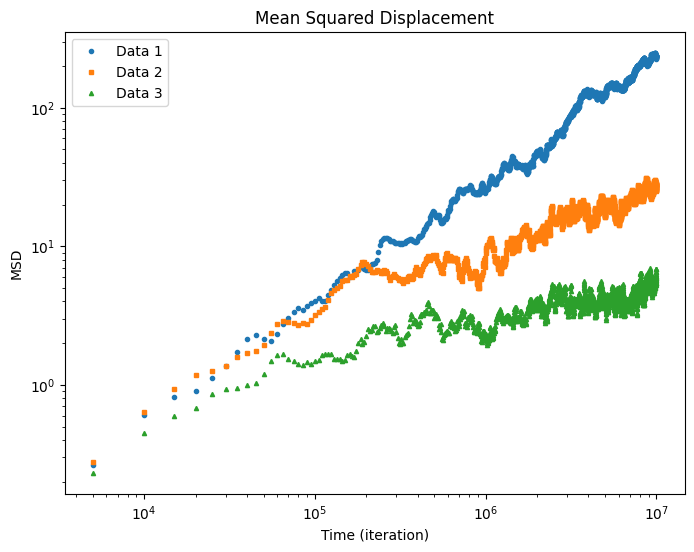

In [4]:
# --------------------------------------------
# Calculate the MSD for all the three datasets
# and plot them
# --------------------------------------------

time1, MSD1 = calculate_MSD(file1)
time2, MSD2 = calculate_MSD(file2)
time3, MSD3 = calculate_MSD(file3)

# --------------------------------------------
# Plot MSD versus time
# --------------------------------------------

plt.figure(figsize=(8,6))

# MSD curves
plt.loglog(
    time1[1:], MSD1[1:],
    'o', markersize=3,
    label=f"Data 1"
)

plt.loglog(
    time2[1:], MSD2[1:],
    's', markersize=3,
    label=f"Data 2"
)

plt.loglog(
    time3[1:], MSD3[1:],
    '^', markersize=3,
    label=f"Data 3"
)

plt.xlabel("Time (iteration)")
plt.ylabel("MSD")

plt.title("Mean Squared Displacement")

plt.legend()

plt.show()

In [5]:
# --------------------------------------------
# 7. Fit MSD = a * t^b
# --------------------------------------------

def power_law(t, a, b):
    return a * t**b


# -------- File 1 --------

start1 = int(0.1 * len(time1))

fit_time1 = time1[start1:]
fit_MSD1 = MSD1[start1:]

parameters1, covariance1 = curve_fit(
    power_law,
    fit_time1,
    fit_MSD1
)
# Standard errors of the fitted parameters
errors1 = np.sqrt(np.diag(covariance1))

a1 = parameters1[0]
b1 = parameters1[1]
a1_error = errors1[0]
b1_error = errors1[1]


# -------- File 2 --------

start2 = int(0.1 * len(time2))

fit_time2 = time2[start2:]
fit_MSD2 = MSD2[start2:]

parameters2, covariance2 = curve_fit(
    power_law,
    fit_time2,
    fit_MSD2
)
# Standard errors of the fitted parameters
errors2 = np.sqrt(np.diag(covariance2))
a2 = parameters2[0]
b2 = parameters2[1]
a2_error = errors2[0]
b2_error = errors2[1]

# -------- File 3 --------

start3 = int(0.1 * len(time3))

fit_time3 = time3[start3:]
fit_MSD3 = MSD3[start3:]

parameters3, covariance3 = curve_fit(
    power_law,
    fit_time3,
    fit_MSD3
)
# Standard errors of the fitted parameters
errors3 = np.sqrt(np.diag(covariance3))
a3 = parameters3[0]
b3 = parameters3[1]
a3_error = errors3[0]
b3_error = errors3[1]


# --------------------------------------------
# 8. Print the result
# --------------------------------------------

print("Power-law fit:")
print("MSD = a * t^b")
print()
print("Data 1:  MSD exponent =", b1, "+/-", b1_error)
print("Data 2:  MSD exponent =", b2, "+/-", b2_error)
print("Data 3:  MSD exponent =", b3, "+/-", b3_error)

Power-law fit:
MSD = a * t^b

Data 1:  MSD exponent = 0.9207761241197681 +/- 0.005488209645747774
Data 2:  MSD exponent = 0.4619547924118172 +/- 0.005789740169191944
Data 3:  MSD exponent = 0.2365325178466395 +/- 0.006427616186415993


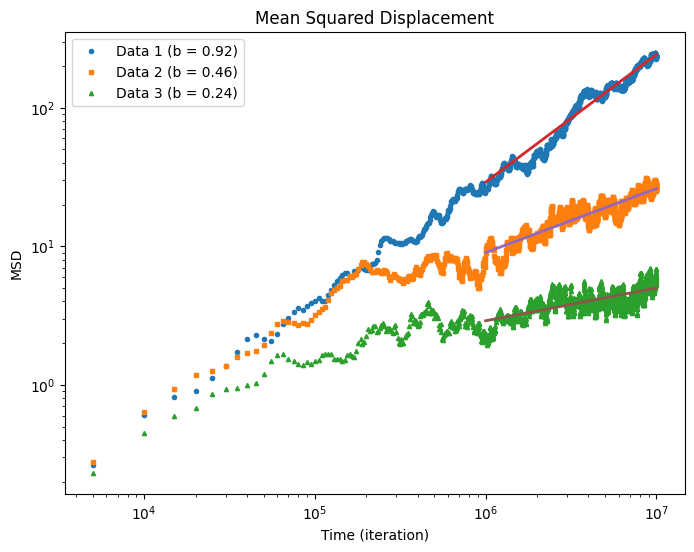

In [6]:
# --------------------------------------------
# 9. Plot the fitted curve
# --------------------------------------------

plt.figure(figsize=(8,6))

# MSD curves
plt.loglog(
    time1[1:], MSD1[1:],
    'o', markersize=3,
    label=f"Data 1 (b = {b1:.2f})"
)

plt.loglog(
    time2[1:], MSD2[1:],
    's', markersize=3,
    label=f"Data 2 (b = {b2:.2f})"
)

plt.loglog(
    time3[1:], MSD3[1:],
    '^', markersize=3,
    label=f"Data 3 (b = {b3:.2f})"
)


# Power-law fits
plt.loglog(
    fit_time1,
    power_law(fit_time1, a1, b1),
    linewidth=2
)

plt.loglog(
    fit_time2,
    power_law(fit_time2, a2, b2),
    linewidth=2
)

plt.loglog(
    fit_time3,
    power_law(fit_time3, a3, b3),
    linewidth=2
)


plt.xlabel("Time (iteration)")
plt.ylabel("MSD")

plt.title("Mean Squared Displacement")

plt.legend()

plt.show()